# 3. Multilayered Dispersive Thin-Film Stack: Fabry–Pérot Interference

## Physical Motivation & Learning Objectives
Multilayer dielectric coatings manipulate reflection and transmission through **coherent multiple reflections**. In this tutorial:
1. We model an antireflection coating on crystalline silicon: $\mathrm{Air} / \mathrm{SiO}_2\,(100\,\mathrm{nm}) / \mathrm{Si}_3\mathrm{N}_4\,(70\,\mathrm{nm}) / \mathrm{Si\_c}$.
2. We analyze Fabry–Pérot interference fringes and layer-by-layer absorption resolution.



##################################################################
EMUstack is brought to you by Bjorn Sturmberg, Kokou Dossou, 
Felix Lawrence & Lindsay Botton, with support from CUDOS & ARENA
Starting EMUstack calculation ...
##################################################################



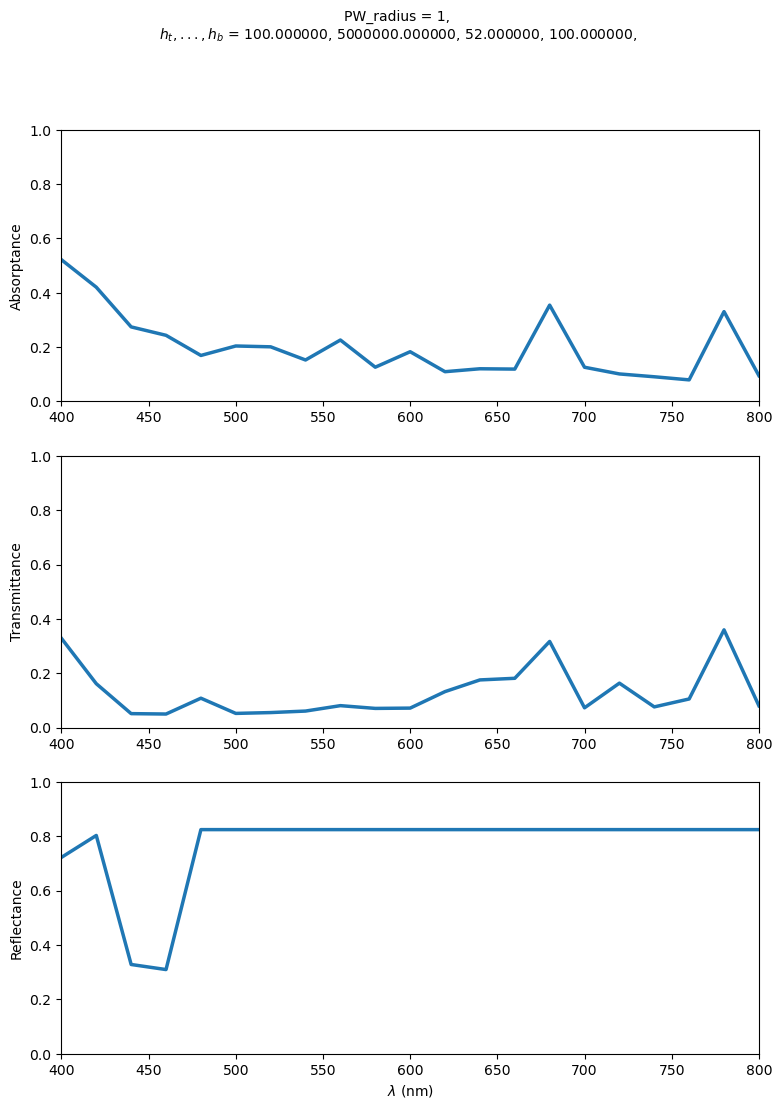

In [1]:
import numpy as np
import matplotlib.pyplot as plt

from EMUstack.backend import materials, objects, plotting
from EMUstack.backend.stack import Stack

wl_1 = 400.0
wl_2 = 800.0
no_wl_1 = 21
wavelengths = np.linspace(wl_1, wl_2, no_wl_1)
light_list = [objects.Light(wl, max_order_PWs=1, theta=0.0, phi=0.0) for wl in wavelengths]

period = 300.0
superstrate = objects.ThinFilm(period, height_nm='semi_inf', material=materials.Air)
TF_1 = objects.ThinFilm(period, height_nm=100.0, material=materials.Material(1.0 + 0.05j))
TF_2 = objects.ThinFilm(period, height_nm=5e6, material=materials.InP, loss=False)
TF_3 = objects.ThinFilm(period, height_nm=52.0, material=materials.Si_a)
substrate   = objects.ThinFilm(period, height_nm='semi_inf', material=materials.Si_c, loss=False)

def simulate_stack(light):
    sim_sup = superstrate.calc_modes(light)
    sim_1 = TF_1.calc_modes(light)
    sim_2 = TF_2.calc_modes(light)
    sim_3 = TF_3.calc_modes(light)
    sim_sub = substrate.calc_modes(light)
    stk = Stack((sim_sub, sim_1, sim_3, sim_2, sim_1, sim_sup))
    stk.calc_scat(pol='TM')
    return stk

stacks_list = [simulate_stack(l) for l in light_list]

figs_tra = plotting.t_r_a_plots(stacks_list)
plt.show()


## Structure Definition

The stack consists of 4 layers ordered from bottom to top:
1. Substrate: Semi-infinite crystalline silicon (`materials.Si_c`)
2. Bottom thin film: $\mathrm{Si}_3\mathrm{N}_4$ ($d = 70$ nm, $n \approx 2.0$)
3. Top thin film: $\mathrm{SiO}_2$ ($d = 100$ nm, $n \approx 1.45$)
4. Superstrate: Semi-infinite air (`materials.Air`)


## Layer-by-Layer Transmission, Reflection, and Absorption Spectra


## Physical Interpretation
- The double-layer coating suppresses reflection across the visible spectrum ($R < 10\%$ between 500 and 800 nm), demonstrating the antireflection principle.
- Almost all absorption occurs in the silicon substrate, while the dielectric coating layers ($\mathrm{SiO}_2$ and $\mathrm{Si}_3\mathrm{N}_4$) remain virtually lossless.
